Attack 1 - False Negatives. Takes about 7 mins to run

In [ ]:

import os
import cv2
import csv
import numpy as np
from deepface import DeepFace


# ============================================================
# 1. EXPERIMENT CONFIGURATION
# ============================================================

# Location of the ORL database.
DATABASE = "attdb"

# Number of subjects in the ORL database.
NUM_SUBJECTS = 40

# Recognition model used for every comparison.
MODEL_NAME = "Facenet"

# Set a random seed so Gaussian noise experiments are reproducible.
rng = np.random.default_rng(42)

# Store every individual comparison here.
trial_results = []

# Store the overall results for each modification.
summary_results = []


# ============================================================
# 2. DEFINE THE MODIFICATIONS TO TEST
# ============================================================

# Each modification has multiple intensity levels.
# The baseline uses the original, unmodified authentication image.

conditions = [
    ("Baseline", "none", None),

    # Brightness: multiply pixel values by the given factor.
    ("Brightness 80%", "brightness", 0.8),
    ("Brightness 60%", "brightness", 0.6),
    ("Brightness 40%", "brightness", 0.4),

    # Blur: progressively increase the Gaussian blur kernel.
    ("Blur 3", "blur", 3),
    ("Blur 5", "blur", 5),
    ("Blur 9", "blur", 9),

    # Noise: standard deviation of the random pixel noise.
    ("Noise 5", "noise", 5),
    ("Noise 15", "noise", 15),
    ("Noise 30", "noise", 30),

    # Occlusion: percentage of image width covered around the eye region.
    ("Occlusion 25%", "occlusion", 0.25),
    ("Occlusion 50%", "occlusion", 0.50),
    ("Occlusion 75%", "occlusion", 0.75),

    # Rotation: degrees clockwise.
    ("Rotation 5", "rotation", 5),
    ("Rotation 10", "rotation", 10),
    ("Rotation 20", "rotation", 20)
]


# ============================================================
# 3. IMAGE MODIFICATION FUNCTION
# ============================================================

# Applies one modification to an authentication image.
# The original enrollment image is never modified.

def modify_image(img, modification, intensity):

    # Baseline: return the original image unchanged.
    if modification == "none":
        return img.copy()

    # Brightness manipulation.
    elif modification == "brightness":
        modified = img.astype(np.float32) * intensity
        return np.clip(modified, 0, 255).astype(np.uint8)

    # Gaussian blur.
    elif modification == "blur":
        return cv2.GaussianBlur(
            img,
            (intensity, intensity),
            0
        )

    # Add random Gaussian noise to the image.
    elif modification == "noise":
        noise = rng.normal(
            0,
            intensity,
            img.shape
        )

        modified = img.astype(np.float32) + noise

        return np.clip(modified, 0, 255).astype(np.uint8)

    # Cover the eye region with a black rectangle.
    elif modification == "occlusion":
        modified = img.copy()

        height, width = img.shape[:2]

        # Determine the dimensions of the covered region.
        mask_width = int(width * intensity)
        mask_height = int(height * intensity * 0.35)

        # Center the mask horizontally around the eyes.
        x1 = (width - mask_width) // 2
        x2 = x1 + mask_width

        # Position the mask around the upper-middle portion.
        y1 = int(height * 0.30)
        y2 = min(y1 + mask_height, height)

        modified[y1:y2, x1:x2] = 0

        return modified

    # Rotate the image around its center.
    elif modification == "rotation":
        height, width = img.shape[:2]

        center = (width // 2, height // 2)

        matrix = cv2.getRotationMatrix2D(
            center,
            intensity,
            1.0
        )

        return cv2.warpAffine(
            img,
            matrix,
            (width, height),
            borderMode=cv2.BORDER_REFLECT
        )


# ============================================================
# 4. RUN THE EXPERIMENT
# ============================================================

# Each subject has 10 images.
# Image 1 is used for enrollment.
# Images 2-10 are used for authentication attempts.

for i in range(1, NUM_SUBJECTS + 1):

    folder = os.path.join(DATABASE, f"s{i}")

    # Get all image files and sort them numerically.
    # Numeric sorting prevents 10.pgm from appearing before 2.pgm.
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".pgm", ".png", ".jpg", ".jpeg"))
    ]

    images.sort(
        key=lambda name: int(os.path.splitext(name)[0])
    )

    # Read the enrollment image.
    enrollment_path = os.path.join(folder, images[0])

    enrollment_img = cv2.imread(
        enrollment_path,
        cv2.IMREAD_GRAYSCALE
    )

    # Convert grayscale to three-channel BGR for DeepFace.
    enrollment_img = cv2.cvtColor(
        enrollment_img,
        cv2.COLOR_GRAY2BGR
    )

    print(f"\nTesting Subject s{i}")

    # Compare every remaining image against the enrollment image.
    for filename in images[1:]:

        test_path = os.path.join(folder, filename)

        test_img = cv2.imread(
            test_path,
            cv2.IMREAD_GRAYSCALE
        )

        test_img = cv2.cvtColor(
            test_img,
            cv2.COLOR_GRAY2BGR
        )

        # Test every modification and intensity.
        for condition, modification, intensity in conditions:

            # Generate a modified copy of the authentication image.
            modified_img = modify_image(
                test_img,
                modification,
                intensity
            )

            # Attempt facial verification.
            try:

                result = DeepFace.verify(
                    img1_path=enrollment_img,
                    img2_path=modified_img,
                    model_name=MODEL_NAME,
                    detector_backend="skip"
                )

                # Record whether DeepFace accepted the identity.
                verified = result["verified"]

                # Record the distance between facial embeddings.
                distance = result["distance"]

                # Record the model's verification threshold.
                threshold = result["threshold"]

                trial_results.append({
                    "subject": f"s{i}",
                    "image": filename,
                    "condition": condition,
                    "verified": verified,
                    "distance": distance,
                    "threshold": threshold,
                    "error": ""
                })

            except Exception as e:

                # Record processing errors separately.
                # A processing error is NOT automatically counted
                # as a false rejection.
                trial_results.append({
                    "subject": f"s{i}",
                    "image": filename,
                    "condition": condition,
                    "verified": None,
                    "distance": None,
                    "threshold": None,
                    "error": str(e)
                })

    print(f"Finished Subject s{i}")


# ============================================================
# 5. CALCULATE OVERALL RESULTS
# ============================================================

# Calculate the false rejection rate for each condition.
# Only successfully completed verification attempts are included.

print("\n========== EXPERIMENT RESULTS ==========")

for condition, modification, intensity in conditions:

    # Get all trials belonging to this modification.
    results = [
        trial for trial in trial_results
        if trial["condition"] == condition
    ]

    # Separate successful verification operations from errors.
    completed = [
        trial for trial in results
        if trial["verified"] is not None
    ]

    # Count accepted and rejected legitimate users.
    accepted = sum(
        trial["verified"] for trial in completed
    )

    rejected = len(completed) - accepted

    errors = len(results) - len(completed)

    # Calculate the false rejection rate.
    frr = (
        rejected / len(completed) * 100
        if completed else 0
    )

    # Save the summary for this condition.
    summary_results.append({
        "condition": condition,
        "accepted": accepted,
        "rejected": rejected,
        "completed": len(completed),
        "errors": errors,
        "FRR": round(frr, 2)
    })

    print(f"\n{condition}")
    print(f"Accepted: {accepted}/{len(completed)}")
    print(f"Rejected: {rejected}/{len(completed)}")
    print(f"Errors: {errors}")
    print(f"False Rejection Rate: {frr:.2f}%")


# ============================================================
# 6. EXPORT RESULTS TO CSV
# ============================================================

# Save individual comparisons so they can be analyzed later.
with open("trial_results_att.csv", "w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=trial_results[0].keys()
    )

    writer.writeheader()
    writer.writerows(trial_results)


# Save the overall results for each modification.
with open("summary_results_att.csv", "w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=summary_results[0].keys()
    )

    writer.writeheader()
    writer.writerows(summary_results)


print("\n========== COMPLETE ==========")
print("Individual results saved to trial_results.csv")
print("Summary results saved to summary_results.csv")



Testing Subject s1
Finished Subject s1

Testing Subject s2
Finished Subject s2

Testing Subject s3
Finished Subject s3

Testing Subject s4
Finished Subject s4

Testing Subject s5
Finished Subject s5

Testing Subject s6
Finished Subject s6

Testing Subject s7
Finished Subject s7

Testing Subject s8
Finished Subject s8

Testing Subject s9
Finished Subject s9

Testing Subject s10
Finished Subject s10

Testing Subject s11
Finished Subject s11

Testing Subject s12
Finished Subject s12

Testing Subject s13
Finished Subject s13

Testing Subject s14
Finished Subject s14

Testing Subject s15
Finished Subject s15

Testing Subject s16
Finished Subject s16

Testing Subject s17
Finished Subject s17

Testing Subject s18
Finished Subject s18

Testing Subject s19
Finished Subject s19

Testing Subject s20
Finished Subject s20

Testing Subject s21
Finished Subject s21

Testing Subject s22
Finished Subject s22

Testing Subject s23
Finished Subject s23

Testing Subject s24
Finished Subject s24

Testing S

Attack 1 - False negatives on Yale DB - takes about 3 mins to run

In [14]:

import os
import cv2
import csv
import numpy as np
from deepface import DeepFace


# ============================================================
# 1. EXPERIMENT CONFIGURATION
# ============================================================

# Location of the Yale database.
DATABASE = "yaledb"

# Recognition model used for every comparison.
MODEL_NAME = "Facenet"

# Set a random seed so Gaussian noise experiments are reproducible.
rng = np.random.default_rng(42)

# Store every individual comparison here.
trial_results = []

# Store the overall results for each modification.
summary_results = []


# ============================================================
# 2. DEFINE THE MODIFICATIONS TO TEST
# ============================================================

# Each modification has multiple intensity levels.
# The baseline uses the original, unmodified authentication image.

conditions = [
    ("Baseline", "none", None),

    # Brightness: multiply pixel values by the given factor.
    ("Brightness 80%", "brightness", 0.8),
    ("Brightness 60%", "brightness", 0.6),
    ("Brightness 40%", "brightness", 0.4),

    # Blur: progressively increase the Gaussian blur kernel.
    ("Blur 3", "blur", 3),
    ("Blur 5", "blur", 5),
    ("Blur 9", "blur", 9),

    # Noise: standard deviation of the random pixel noise.
    ("Noise 5", "noise", 5),
    ("Noise 15", "noise", 15),
    ("Noise 30", "noise", 30),

    # Occlusion: percentage of image width covered around the eye region.
    ("Occlusion 25%", "occlusion", 0.25),
    ("Occlusion 50%", "occlusion", 0.50),
    ("Occlusion 75%", "occlusion", 0.75),

    # Rotation: degrees clockwise.
    ("Rotation 5", "rotation", 5),
    ("Rotation 10", "rotation", 10),
    ("Rotation 20", "rotation", 20)
]


# ============================================================
# 3. IMAGE MODIFICATION FUNCTION
# ============================================================

# Applies one modification to an authentication image.
# The original enrollment image is never modified.

def modify_image(img, modification, intensity):

    # Baseline: return the original image unchanged.
    if modification == "none":
        return img.copy()

    # Brightness manipulation.
    elif modification == "brightness":
        modified = img.astype(np.float32) * intensity
        return np.clip(modified, 0, 255).astype(np.uint8)

    # Gaussian blur.
    elif modification == "blur":
        return cv2.GaussianBlur(
            img,
            (intensity, intensity),
            0
        )

    # Add random Gaussian noise to the image.
    elif modification == "noise":
        noise = rng.normal(
            0,
            intensity,
            img.shape
        )

        modified = img.astype(np.float32) + noise

        return np.clip(modified, 0, 255).astype(np.uint8)

    # Cover the eye region with a black rectangle.
    elif modification == "occlusion":
        modified = img.copy()

        height, width = img.shape[:2]

        # Determine the dimensions of the covered region.
        mask_width = int(width * intensity)
        mask_height = int(height * intensity * 0.35)

        # Center the mask horizontally around the eyes.
        x1 = (width - mask_width) // 2
        x2 = x1 + mask_width

        # Position the mask around the upper-middle portion.
        y1 = int(height * 0.30)
        y2 = min(y1 + mask_height, height)

        modified[y1:y2, x1:x2] = 0

        return modified

    # Rotate the image around its center.
    elif modification == "rotation":
        height, width = img.shape[:2]

        center = (width // 2, height // 2)

        matrix = cv2.getRotationMatrix2D(
            center,
            intensity,
            1.0
        )

        return cv2.warpAffine(
            img,
            matrix,
            (width, height),
            borderMode=cv2.BORDER_REFLECT
        )


# ============================================================
# 4. GROUP IMAGES BY SUBJECT
# ============================================================

subjects = {}

# Read every image in the Yale database.
for filename in os.listdir(DATABASE):

    # Only include files beginning with "subject".
    if filename.startswith("subject"):

        # Everything before the period identifies the subject.
        subject = filename.split(".")[0]

        if subject not in subjects:
            subjects[subject] = []

        subjects[subject].append(filename)


# ============================================================
# 5. RUN THE EXPERIMENT
# ============================================================

# Each subject's first alphabetically sorted image is used
# for enrollment.
# All remaining images are used for authentication attempts.

for subject, images in sorted(subjects.items()):

    # Sort images consistently.
    images.sort()

    print(f"\nTesting {subject}")

    # Read the enrollment image.
    enrollment_path = os.path.join(DATABASE, images[0])

    enrollment_img = cv2.imread(
        enrollment_path,
        cv2.IMREAD_GRAYSCALE
    )

    # Convert grayscale to three-channel BGR for DeepFace.
    enrollment_img = cv2.cvtColor(
        enrollment_img,
        cv2.COLOR_GRAY2BGR
    )

    # Compare every remaining image against the enrollment image.
    for filename in images[1:]:

        test_path = os.path.join(DATABASE, filename)

        test_img = cv2.imread(
            test_path,
            cv2.IMREAD_GRAYSCALE
        )

        test_img = cv2.cvtColor(
            test_img,
            cv2.COLOR_GRAY2BGR
        )

        # Test every modification and intensity.
        for condition, modification, intensity in conditions:

            # Generate a modified copy of the authentication image.
            modified_img = modify_image(
                test_img,
                modification,
                intensity
            )

            # Attempt facial verification.
            try:

                result = DeepFace.verify(
                    img1_path=enrollment_img,
                    img2_path=modified_img,
                    model_name=MODEL_NAME,
                    detector_backend="skip"
                )

                # Record whether DeepFace accepted the identity.
                verified = result["verified"]

                # Record the distance between facial embeddings.
                distance = result["distance"]

                # Record the model's verification threshold.
                threshold = result["threshold"]

                trial_results.append({
                    "subject": subject,
                    "image": filename,
                    "condition": condition,
                    "verified": verified,
                    "distance": distance,
                    "threshold": threshold,
                    "error": ""
                })

            except Exception as e:

                # Record processing errors separately.
                # A processing error is NOT automatically counted
                # as a false rejection.
                trial_results.append({
                    "subject": subject,
                    "image": filename,
                    "condition": condition,
                    "verified": None,
                    "distance": None,
                    "threshold": None,
                    "error": str(e)
                })

    print(f"Finished {subject}")


# ============================================================
# 6. CALCULATE OVERALL RESULTS
# ============================================================

# Calculate the false rejection rate for each condition.
# Only successfully completed verification attempts are included.

print("\n========== EXPERIMENT RESULTS ==========")

for condition, modification, intensity in conditions:

    # Get all trials belonging to this modification.
    results = [
        trial for trial in trial_results
        if trial["condition"] == condition
    ]

    # Separate successful verification operations from errors.
    completed = [
        trial for trial in results
        if trial["verified"] is not None
    ]

    # Count accepted and rejected legitimate users.
    accepted = sum(
        trial["verified"] for trial in completed
    )

    rejected = len(completed) - accepted

    errors = len(results) - len(completed)

    # Calculate the false rejection rate.
    frr = (
        rejected / len(completed) * 100
        if completed else 0
    )

    # Save the summary for this condition.
    summary_results.append({
        "condition": condition,
        "accepted": accepted,
        "rejected": rejected,
        "completed": len(completed),
        "errors": errors,
        "FRR": round(frr, 2)
    })

    print(f"\n{condition}")
    print(f"Accepted: {accepted}/{len(completed)}")
    print(f"Rejected: {rejected}/{len(completed)}")
    print(f"Errors: {errors}")
    print(f"False Rejection Rate: {frr:.2f}%")


# ============================================================
# 7. EXPORT RESULTS TO CSV
# ============================================================

# Save individual comparisons.
with open("trial_results_yale.csv", "w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=trial_results[0].keys()
    )

    writer.writeheader()
    writer.writerows(trial_results)


# Save the overall results for each modification.
with open("summary_results_yale.csv", "w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=summary_results[0].keys()
    )

    writer.writeheader()
    writer.writerows(summary_results)


print("\n========== COMPLETE ==========")
print("Individual results saved to trial_results_yale.csv")
print("Summary results saved to summary_results_yale.csv")



Testing subject01
Finished subject01

Testing subject02
Finished subject02

Testing subject03
Finished subject03

Testing subject04
Finished subject04

Testing subject05
Finished subject05

Testing subject06
Finished subject06

Testing subject07
Finished subject07

Testing subject08
Finished subject08

Testing subject09
Finished subject09

Testing subject10
Finished subject10

Testing subject11
Finished subject11

Testing subject12
Finished subject12

Testing subject13
Finished subject13

Testing subject14
Finished subject14

Testing subject15
Finished subject15

========== EXPERIMENT RESULTS ==========

Baseline
Accepted: 125/150
Rejected: 25/150
Errors: 0
False Rejection Rate: 16.67%

Brightness 80%
Accepted: 124/150
Rejected: 26/150
Errors: 0
False Rejection Rate: 17.33%

Brightness 60%
Accepted: 120/150
Rejected: 30/150
Errors: 0
False Rejection Rate: 20.00%

Brightness 40%
Accepted: 101/150
Rejected: 49/150
Errors: 0
False Rejection Rate: 32.67%

Blur 3
Accepted: 124/150
Rejected

Yale example of what each factor is actually visually doing to the image

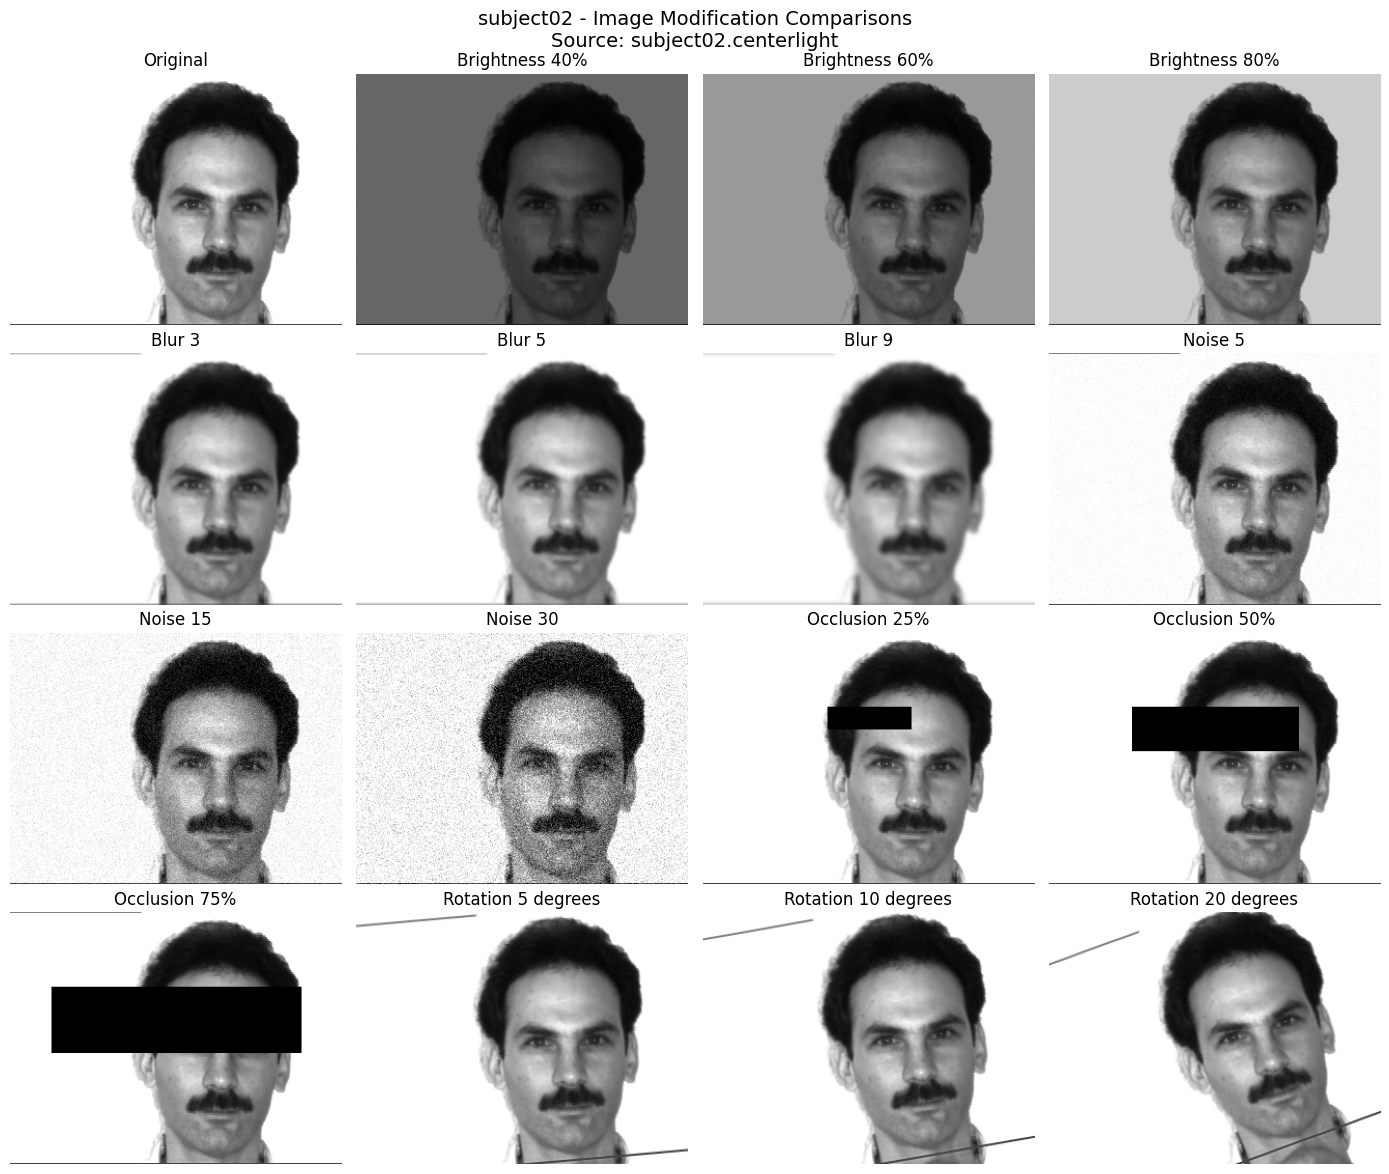

In [26]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Folder containing the Yale face dataset
DATABASE = "yaledb"

# Choose which subject you want to examine
SUBJECT = "subject02"

# Random generator so the noise examples stay consistent
rng = np.random.default_rng(42)


# Apply one modification to an image
def modify_image(img, modification, intensity):

    # Brightness: multiply pixel values by the selected percentage
    if modification == "brightness":
        modified = img.astype(np.float32) * intensity
        return np.clip(modified, 0, 255).astype(np.uint8)

    # Blur: apply Gaussian blur using the selected kernel size
    elif modification == "blur":
        return cv2.GaussianBlur(img, (intensity, intensity), 0)

    # Noise: add random Gaussian noise to the image
    elif modification == "noise":
        noise = rng.normal(0, intensity, img.shape)
        modified = img.astype(np.float32) + noise
        return np.clip(modified, 0, 255).astype(np.uint8)

    # Occlusion: cover part of the eye region with a black rectangle
    elif modification == "occlusion":
        modified = img.copy()

        height, width = img.shape[:2]
        mask_width = int(width * intensity)
        mask_height = int(height * intensity * 0.35)

        x_start = (width - mask_width) // 2
        y_start = int(height * 0.30)

        cv2.rectangle(
            modified,
            (x_start, y_start),
            (x_start + mask_width, y_start + mask_height),
            0,
            -1
        )

        return modified

    # Rotation: rotate the image by the selected number of degrees
    elif modification == "rotation":
        height, width = img.shape[:2]

        center = (width // 2, height // 2)
        matrix = cv2.getRotationMatrix2D(center, intensity, 1.0)

        return cv2.warpAffine(
            img,
            matrix,
            (width, height),
            borderMode=cv2.BORDER_REFLECT
        )

    return img.copy()


# Define all image modifications and their intensity values
conditions = [
    ("Original", "none", None),

    ("Brightness 40%", "brightness", 0.40),
    ("Brightness 60%", "brightness", 0.60),
    ("Brightness 80%", "brightness", 0.80),

    ("Blur 3", "blur", 3),
    ("Blur 5", "blur", 5),
    ("Blur 9", "blur", 9),

    ("Noise 5", "noise", 5),
    ("Noise 15", "noise", 15),
    ("Noise 30", "noise", 30),

    ("Occlusion 25%", "occlusion", 0.25),
    ("Occlusion 50%", "occlusion", 0.50),
    ("Occlusion 75%", "occlusion", 0.75),

    ("Rotation 5 degrees", "rotation", 5),
    ("Rotation 10 degrees", "rotation", 10),
    ("Rotation 20 degrees", "rotation", 20)
]


# Find all images belonging to the selected subject
subject_images = [
    filename for filename in os.listdir(DATABASE)
    if filename.startswith(SUBJECT + ".")
]

subject_images.sort()

# Check that the selected subject exists
if not subject_images:
    raise FileNotFoundError(f"No images found for {SUBJECT}")

# Load the first image for this subject
image_path = os.path.join(DATABASE, subject_images[0])
original_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if original_image is None:
    raise ValueError(f"Could not load image: {image_path}")


# Create a figure showing the original and modified images
columns = 4
rows = int(np.ceil(len(conditions) / columns))

plt.figure(figsize=(14, rows * 3))

for i, (label, modification, intensity) in enumerate(conditions):

    # Keep the original image unchanged
    if modification == "none":
        modified_image = original_image.copy()

    # Apply the selected modification
    else:
        modified_image = modify_image(
            original_image,
            modification,
            intensity
        )

    # Display the image in its own subplot
    plt.subplot(rows, columns, i + 1)
    plt.imshow(modified_image, cmap="gray", vmin=0, vmax=255)
    plt.title(label)
    plt.axis("off")


# Add a title identifying the selected subject and source image
plt.suptitle(
    f"{SUBJECT} - Image Modification Comparisons\n"
    f"Source: {subject_images[0]}",
    fontsize=14
)

plt.tight_layout()
plt.show()


ATT example of what each factor is actually visually doing to the image

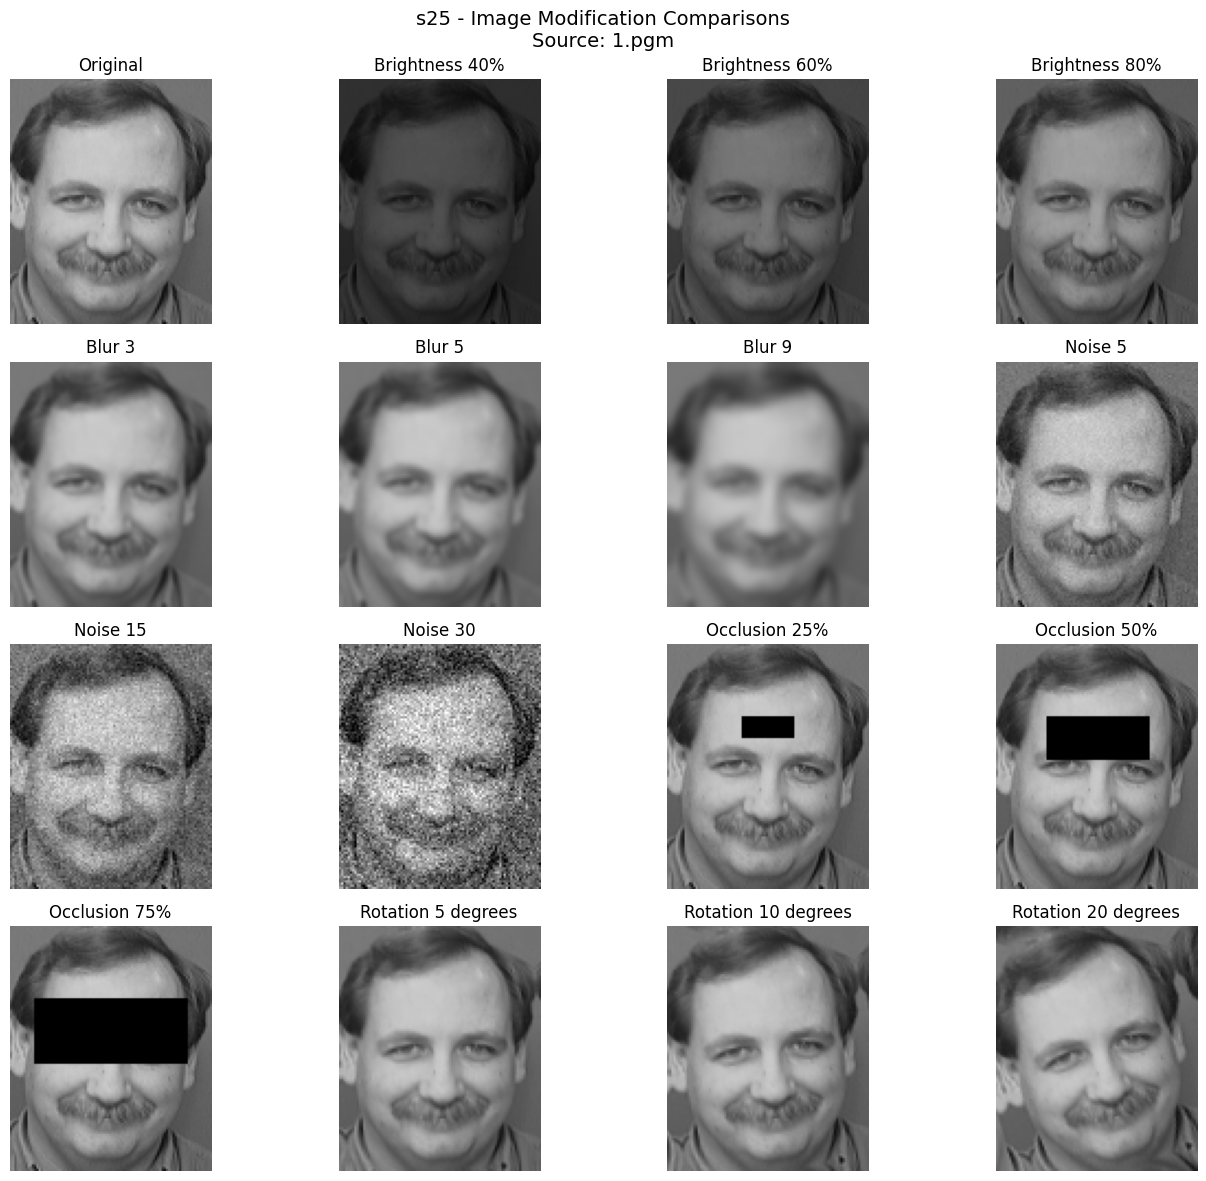

In [30]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Folder containing the AT&T face dataset
DATABASE = "attdb"

# Choose which subject you want to examine (s1 through s40)
SUBJECT = "s25"

# Random generator so the noise examples stay consistent
rng = np.random.default_rng(42)


# Apply one modification to an image
def modify_image(img, modification, intensity):

    # Brightness: multiply pixel values by the selected percentage
    if modification == "brightness":
        modified = img.astype(np.float32) * intensity
        return np.clip(modified, 0, 255).astype(np.uint8)

    # Blur: apply Gaussian blur using the selected kernel size
    elif modification == "blur":
        return cv2.GaussianBlur(img, (intensity, intensity), 0)

    # Noise: add random Gaussian noise to the image
    elif modification == "noise":
        noise = rng.normal(0, intensity, img.shape)
        modified = img.astype(np.float32) + noise
        return np.clip(modified, 0, 255).astype(np.uint8)

    # Occlusion: cover part of the eye region with a black rectangle
    elif modification == "occlusion":
        modified = img.copy()

        height, width = img.shape[:2]
        mask_width = int(width * intensity)
        mask_height = int(height * intensity * 0.35)

        x_start = (width - mask_width) // 2
        y_start = int(height * 0.30)

        cv2.rectangle(
            modified,
            (x_start, y_start),
            (x_start + mask_width, y_start + mask_height),
            0,
            -1
        )

        return modified

    # Rotation: rotate the image by the selected number of degrees
    elif modification == "rotation":
        height, width = img.shape[:2]

        center = (width // 2, height // 2)
        matrix = cv2.getRotationMatrix2D(center, intensity, 1.0)

        return cv2.warpAffine(
            img,
            matrix,
            (width, height),
            borderMode=cv2.BORDER_REFLECT
        )

    return img.copy()


# Define all image modifications and their intensity values
conditions = [
    ("Original", "none", None),

    ("Brightness 40%", "brightness", 0.40),
    ("Brightness 60%", "brightness", 0.60),
    ("Brightness 80%", "brightness", 0.80),

    ("Blur 3", "blur", 3),
    ("Blur 5", "blur", 5),
    ("Blur 9", "blur", 9),

    ("Noise 5", "noise", 5),
    ("Noise 15", "noise", 15),
    ("Noise 30", "noise", 30),

    ("Occlusion 25%", "occlusion", 0.25),
    ("Occlusion 50%", "occlusion", 0.50),
    ("Occlusion 75%", "occlusion", 0.75),

    ("Rotation 5 degrees", "rotation", 5),
    ("Rotation 10 degrees", "rotation", 10),
    ("Rotation 20 degrees", "rotation", 20)
]


# Find all images belonging to the selected subject
subject_folder = os.path.join(DATABASE, SUBJECT)

if not os.path.isdir(subject_folder):
    raise FileNotFoundError(f"Subject folder not found: {subject_folder}")

# Get the image files from the subject's folder
subject_images = [
    filename for filename in os.listdir(subject_folder)
    if filename.lower().endswith((".pgm", ".png", ".jpg", ".jpeg"))
]

# Sort images numerically (1.pgm, 2.pgm, etc.)
subject_images.sort(
    key=lambda filename: int(os.path.splitext(filename)[0])
)

# Check that the selected subject has images
if not subject_images:
    raise FileNotFoundError(f"No images found for {SUBJECT}")

# Load the first image for this subject
image_path = os.path.join(subject_folder, subject_images[0])
original_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if original_image is None:
    raise ValueError(f"Could not load image: {image_path}")


# Create a figure showing the original and modified images
columns = 4
rows = int(np.ceil(len(conditions) / columns))

plt.figure(figsize=(14, rows * 3))

for i, (label, modification, intensity) in enumerate(conditions):

    # Keep the original image unchanged
    if modification == "none":
        modified_image = original_image.copy()

    # Apply the selected modification
    else:
        modified_image = modify_image(
            original_image,
            modification,
            intensity
        )

    # Display the image in its own subplot
    plt.subplot(rows, columns, i + 1)
    plt.imshow(modified_image, cmap="gray", vmin=0, vmax=255)
    plt.title(label)
    plt.axis("off")


# Add a title identifying the selected subject and source image
plt.suptitle(
    f"{SUBJECT} - Image Modification Comparisons\n"
    f"Source: {subject_images[0]}",
    fontsize=14
)

plt.tight_layout()
plt.show()


Visualizations of the summaries

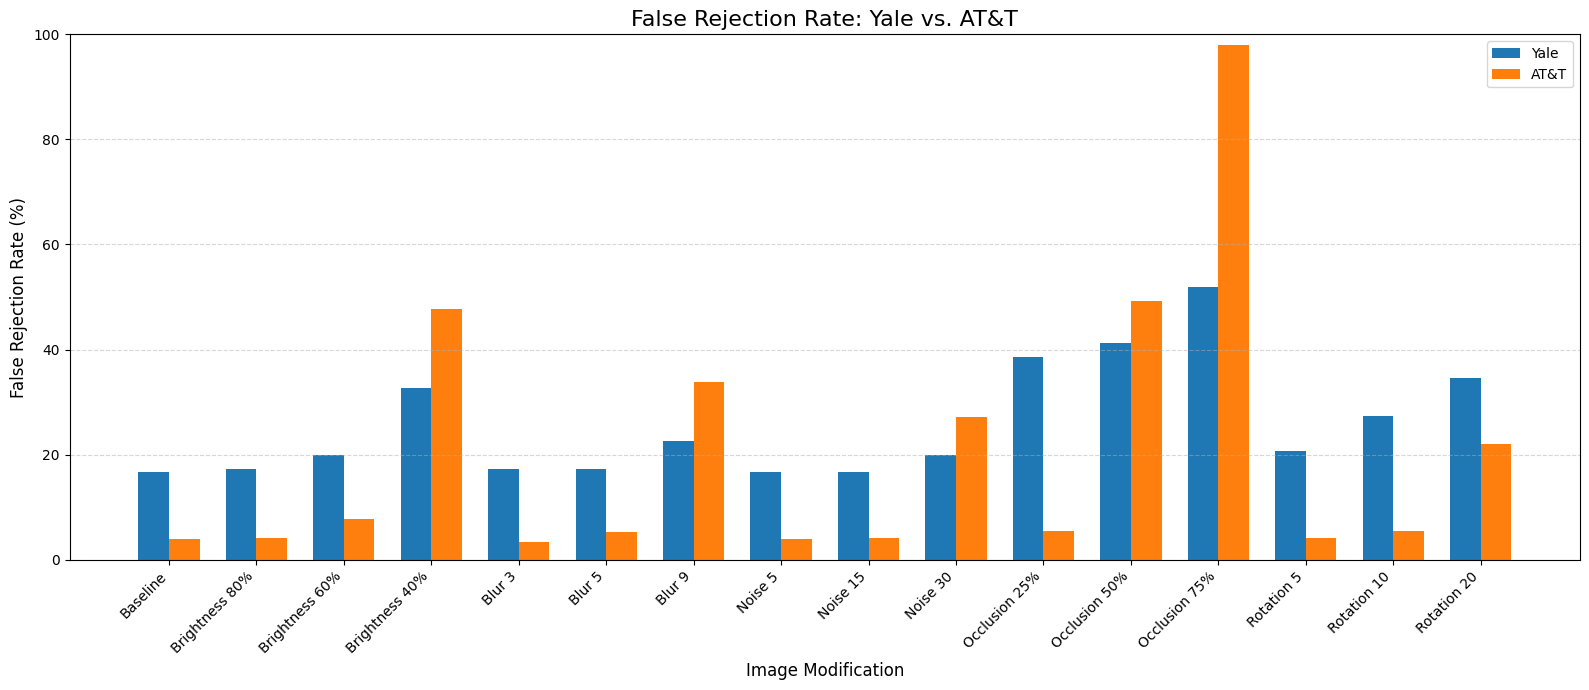

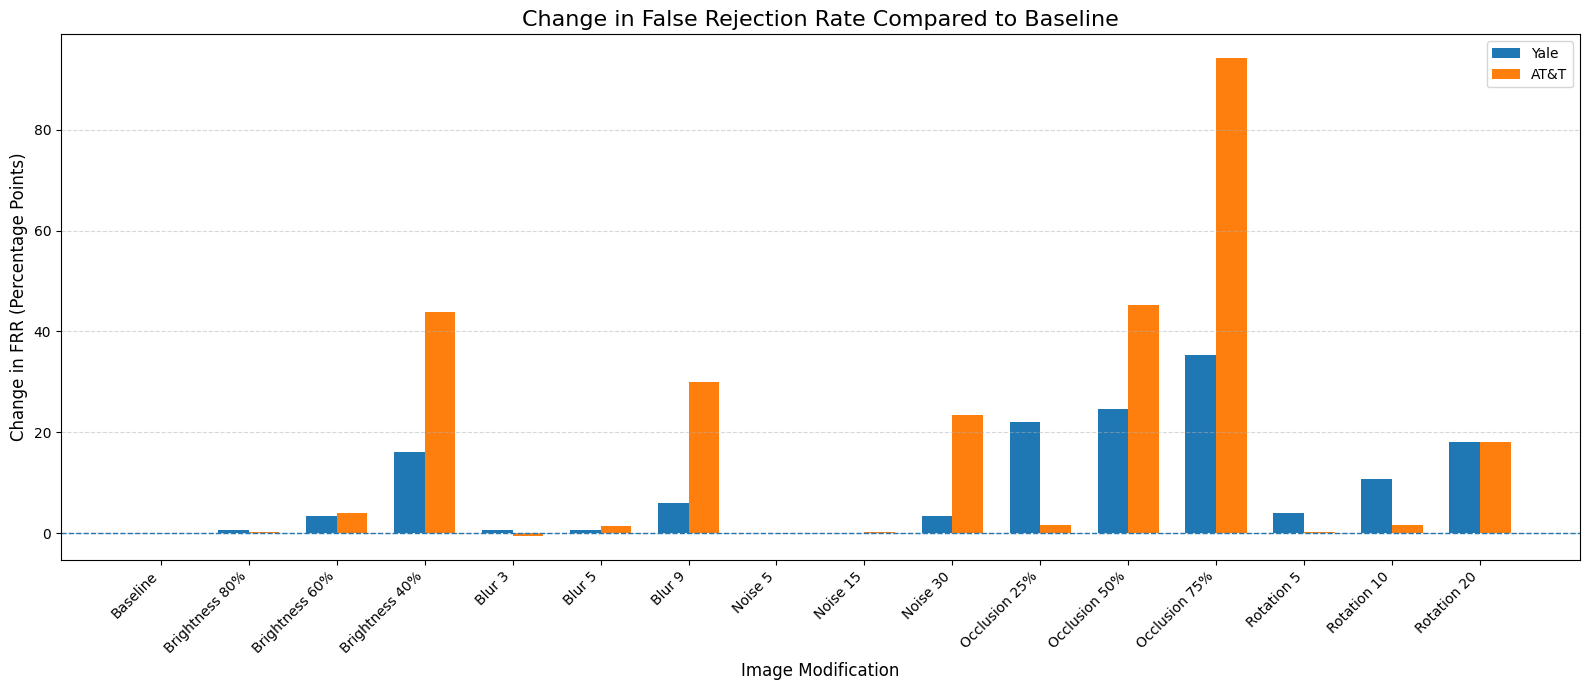

In [17]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the summary CSV files for both datasets
yale = pd.read_csv("summary_results_yale.csv")
att = pd.read_csv("summary_results_att.csv")


# Keep the conditions in a consistent order across both datasets
condition_order = [
    "Baseline",
    "Brightness 80%",
    "Brightness 60%",
    "Brightness 40%",
    "Blur 3",
    "Blur 5",
    "Blur 9",
    "Noise 5",
    "Noise 15",
    "Noise 30",
    "Occlusion 25%",
    "Occlusion 50%",
    "Occlusion 75%",
    "Rotation 5",
    "Rotation 10",
    "Rotation 20"
]

# Reorder the rows so matching conditions appear together
yale = yale.set_index("condition").reindex(condition_order)
att = att.set_index("condition").reindex(condition_order)

# Get the FRR values from each dataset
yale_frr = yale["FRR"]
att_frr = att["FRR"]


# --------------------------------------------------
# GRAPH 1: Compare FRR between Yale and AT&T
# --------------------------------------------------

# Set up the positions of the bars
x = np.arange(len(condition_order))
bar_width = 0.35

plt.figure(figsize=(16, 7))

# Create one bar for each dataset at every condition
plt.bar(
    x - bar_width / 2,
    yale_frr,
    bar_width,
    label="Yale"
)

plt.bar(
    x + bar_width / 2,
    att_frr,
    bar_width,
    label="AT&T"
)

# Add labels and formatting
plt.title("False Rejection Rate: Yale vs. AT&T", fontsize=16)
plt.xlabel("Image Modification", fontsize=12)
plt.ylabel("False Rejection Rate (%)", fontsize=12)

plt.xticks(x, condition_order, rotation=45, ha="right")
plt.ylim(0, 100)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("frr_comparison.png", dpi=300)
plt.show()


# --------------------------------------------------
# GRAPH 2: Increase in FRR Compared to Baseline
# --------------------------------------------------

# Calculate how much FRR increased from each dataset's baseline
yale_baseline = yale_frr["Baseline"]
att_baseline = att_frr["Baseline"]

yale_change = yale_frr - yale_baseline
att_change = att_frr - att_baseline

plt.figure(figsize=(16, 7))

# Create grouped bars for the change in FRR
plt.bar(
    x - bar_width / 2,
    yale_change,
    bar_width,
    label="Yale"
)

plt.bar(
    x + bar_width / 2,
    att_change,
    bar_width,
    label="AT&T"
)

# Add a horizontal line at zero to represent baseline performance
plt.axhline(y=0, linestyle="--", linewidth=1)

# Add labels and formatting
plt.title("Change in False Rejection Rate Compared to Baseline", fontsize=16)
plt.xlabel("Image Modification", fontsize=12)
plt.ylabel("Change in FRR (Percentage Points)", fontsize=12)

plt.xticks(x, condition_order, rotation=45, ha="right")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("frr_change_comparison.png", dpi=300)
plt.show()
